# CS4 - Making the Most of an Imperfect Well (16/7-1)

**Petrophys Case Studies - the honesty & robustness study**

---

## 1. The brief

> *"Well 16/7-1 is the only log data we have over this fault block. It is old, and it is
> incomplete: there is no neutron log, no PEF, the deep resistivity reads thousands of ohm.m
> over a long section, and there are washout zones. Management still needs a defensible
> porosity and net-pay number to decide whether to carry this prospect forward. Give us the
> best interpretation you honestly can - and be explicit about which parts of it we can trust
> and which parts rest on synthetic data."*

This is the situation every petrophysicist eventually faces: a real, imperfect well and a
decision that cannot wait for a perfect dataset. The professional answer is **not** to refuse,
and it is **not** to quietly paper over the gaps. It is to:

1. **Inventory** exactly what was measured and what is missing (a *data readiness* assessment).
2. **Flag** the detectable problems (resistivity beyond the tool's reliable range, a sonic on
   the wrong scale, washout) transparently - flagged out, not silently corrected - and find out
   *why* each one happens.
3. **Reconstruct** the genuinely-missing curves with a *validated* model - and prove the model
   is credible on this well before trusting it.
4. **Interpret** with the mixed measured + synthetic dataset, carrying an **uncertainty flag**
   on every interval that leans on synthetic data.
5. **Deliver** a caveated answer that a reviewer can audit line by line.

The deliverable is a **data readiness report** (measured vs imputed) plus a **caveated net-pay
result** that is honest about which parts rest on imputed data.

### How this differs from CS1-CS3
CS1 evaluated a well with a full log suite, core and a documented Rw; CS2 and CS3 had
core-derived curves and near-complete suites. CS4 has none of that luxury. The emphasis here is entirely on **QC, imputation, validation and
uncertainty communication** - the parts of the job that separate a defensible interpretation
from a dangerous one. We reference the interpretation mechanics taught in the Part A/B tutorials
rather than re-deriving them.

### What you will learn

- How to build a data-readiness table against a standard log suite.
- How to flag out-of-range resistivity and washouts instead of silently correcting them - and how
  to tell a real rock response (evaporites) from a tool problem.
- How to catch a curve stored on the wrong scale before it feeds a model.
- How to validate an imputer with a blank-and-restore test before trusting it - and what that
  test does *not* tell you.
- How to split net pay into firm and uncertain parts, with every assumption stated.

### Prerequisites

Lessons 02 (QC and standardization), 04 (porosity), 07 (water saturation) and **13 (ML curve
imputation)**. This case study needs the optional ML extra in the notebook kernel:

```bash
python -m pip install -e ".[ml]"      # from a repository checkout
# or: python -m pip install "petrophys[ml]"
```

The pretrained models need **Python 3.11 or later**; on older Pythons the extra installs nothing
and Section 4.4 fails with an import error. The model loader checks dependency versions; do not
suppress its version warnings to bypass that check (lesson 13).

## Setup

We load `petrophys`, matplotlib (inline so figures embed), and the specific QC / imputation
tools this study needs. All data is bundled with the library - no external files. No warnings
are silenced: if the ML model pack reports a version mismatch, fix the environment rather than
hiding the message.

In [1]:
%matplotlib inline
from petrophys.visualization import use_plot_style
use_plot_style()
import copy

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import petrophys as pp

# QC tools
from petrophys.preprocessing import (
    apply_value_range_qc,
    value_range_qc_note,
    detect_washout,
)
# ML curve imputation (needs the [ml] extra, Python 3.11+)
from petrophys.preprocessing.imputation import (
    PretrainedCurveImputer,
    default_pretrained_model_path,
)
# Interpretation
from petrophys.interpretation.clay_volume import vcl_from_gr
from petrophys.interpretation.porosity import density_porosity, nd_weighted_porosity, effective_porosity
from petrophys.interpretation.saturation import archie

print("petrophys", pp.__version__)
print("GeoLink sample wells:", pp.list_samples("geolink"))

petrophys 3.0.0
GeoLink sample wells: ['15_9-14', '16_7-1', '25_5-1', '30_6-5']


## 2. The well & data - a first look

**16/7-1** is a GeoLink North Sea well logged in metres. Let us load it and see exactly what
curves survived digitisation.

In [2]:
well = pp.read(pp.sample("16_7-1"))

print("Well name    :", well.name)
print("Depth unit   :", well.depth_unit)
print("Interval     : %.1f - %.1f %s" % (well.top, well.bottom, well.depth_unit))
print("Sample step  : %.4f %s" % (well.step, well.depth_unit))
print("N samples    :", well.n_samples)
print("N curves     :", well.n_curves)
print()
print("Curves present:")
for c in well.curves:
    print("  -", c)

Well name    : 16/7-1
Depth unit   : m
Interval     : 367.9 - 2651.7 m
Sample step  : 0.1524 m
N samples    : 14986
N curves     : 12

Curves present:
  - LITHOLOGY_GEOLINK
  - DCAL
  - CALI
  - BS
  - DRHO
  - RHOB
  - GR
  - DTC
  - RDEP
  - SP
  - RSHA
  - RMED


Twelve curves. Three things jump out immediately for anyone who has done a formation
evaluation:

- There is a **GR, RHOB, DTC (sonic), SP and a full resistivity suite (RDEP/RMED/RSHA)** - a
  workable backbone.
- There is **no NPHI (neutron)** and **no PEF**. The neutron-density crossplot - the workhorse
  for porosity and gas detection - is off the table until we do something about it.
- There is a **CALI, BS and DCAL** (differential caliper), which is exactly what we need to
  find washout.

Before trusting any of it, we quantify *how complete* each curve actually is.

## 3. Workflow plan

The order below is deliberate - each step de-risks the next:

| # | Step | Why here |
|---|------|----------|
| 1 | **Data readiness**: null coverage per curve against a standard log suite | Know the gaps before touching the data |
| 2 | **RDEP above the tool's reliable range**: detect, null via `apply_value_range_qc`, explain by lithology | Readings above 2000 ohm.m cannot feed Sw; here they mark the Zechstein evaporites |
| 3 | **Washout**: `detect_washout` via CALI-BS / DRHO | Flag intervals where RHOB (and thus porosity) is unreliable |
| 4 | **Validate the imputer**: blank-and-restore on a *present* curve (RHOB) | Never trust a synthetic curve you have not error-checked on real data |
| 5 | **Predict the missing NPHI** with the pretrained model - a deliberate, flagged override | Show what a never-logged prediction looks like, and where it fails |
| 6 | **Interpret**: Vcl -> porosity -> Archie Sw on measured curves (+ imputed NPHI for support) | The actual evaluation |
| 7 | **Net pay with uncertainty flags** | The caveated deliverable |

The golden rule threaded through all of it: **anything derived from a synthetic curve inherits
the synthetic curve's uncertainty**, and we track that explicitly.

## 4. Execution

### 4.1 Data readiness - null coverage per curve

A curve can be *present* in the LAS header but still be mostly null. We compute, for every curve
of a standard open-hole log suite, the valid-sample fraction and flag the ones that are missing or
only partly recorded.

In [3]:
# A standard open-hole suite for a clastic evaluation - our "expected" curve list.
STANDARD_SUITE = ["GR", "SP", "CALI", "BS", "DCAL", "RHOB", "DRHO", "NPHI", "PEF", "DTC",
                  "RDEP", "RMED", "RSHA"]

rows = []
for c in STANDARD_SUITE:
    if well.has_curve(c):
        cu = well.get(c)
        valid = cu.valid_count()
        rows.append({
            "curve": c, "status": "present",
            "valid": valid, "null": cu.null_count(),
            "coverage_%": round(100.0 * valid / well.n_samples, 1),
            "min": round(float(np.nanmin(cu.data)), 3) if valid else np.nan,
            "max": round(float(np.nanmax(cu.data)), 3) if valid else np.nan,
        })
    else:
        rows.append({"curve": c, "status": "MISSING", "valid": 0, "null": well.n_samples,
                     "coverage_%": 0.0, "min": np.nan, "max": np.nan})

readiness = pd.DataFrame(rows).sort_values("coverage_%").reset_index(drop=True)
print(readiness.to_string(index=False))

curve  status  valid  null  coverage_%       min      max
 NPHI MISSING      0 14986         0.0       NaN      NaN
  PEF MISSING      0 14986         0.0       NaN      NaN
 RMED present   7101  7885        47.4    -0.013    2.356
 RHOB present   7980  7006        53.2     1.732    2.961
 DRHO present   7980  7006        53.2    -0.066    0.089
  DTC present   9427  5559        62.9    14.896   56.205
 RDEP present  14777   209        98.6    -0.023 4858.222
   GR present  14871   115        99.2     1.225  117.510
 RSHA present  14938    48        99.7     0.059   65.879
   SP present  14985     1       100.0 -6183.089   96.838
 CALI present  14986     0       100.0     5.701   21.995
   BS present  14986     0       100.0     8.500   17.500
 DCAL present  14986     0       100.0    -6.496   12.036


Reading the table top-to-bottom:

- **NPHI and PEF: MISSING** (0% coverage) - genuinely absent.
- **RMED, DRHO, RHOB, DTC: partial coverage** (roughly half to two-thirds of the hole) - these
  were only recorded over part of the well. RHOB/DRHO share the same null pattern (same density
  tool run).
- **GR, RDEP, RSHA, CALI, BS, DCAL, SP: near-100%** - our backbone and QC curves.
- **RDEP max** runs to thousands of ohm.m. That is far above anything a water- or oil-bearing
  clastic reads, but it is the *normal* response of evaporites: halite and anhydrite are almost
  perfect insulators. Section 4.2 shows that is what these readings are.
- **DTC range** is 15-56 us/ft. No rock is that fast: the matrix limits are about 43-55 us/ft
  (dolomite to quartz), halite reads about 67 us/ft and soft shallow mudstones well above
  100 us/ft. The next cell checks the scale.
- **SP min** is thousands of mV negative - physically impossible (real SP anomalies are at most
  a few hundred mV); the value-range QC in the next section screens SP to a -500..+500 mV window
  and nulls these spikes.



In [4]:
# Sonic plausibility: compare DTC with textbook values in two well-known settings.
lith_code = well.get("LITHOLOGY_GEOLINK").data
dtc = well.get("DTC").data
shallow = well.depth < 2000.0                     # Tertiary mudstones above the salt
halite = lith_code == 21                          # GeoLink code 21 = halite
finite_dtc = dtc[np.isfinite(dtc)]
print("DTC median above 2000 m : %5.1f us/ft  (soft Tertiary section: expect > 100)" % np.nanmedian(dtc[shallow]))
print("DTC median in halite    : %5.1f us/ft  (halite: about 67)" % np.nanmedian(dtc[halite]))
print("Ratio halite median / 67: %5.2f" % (np.nanmedian(dtc[halite]) / 67.0))
print("Samples faster than 38.5 us/ft (no rock is): %.0f %%" % (100.0 * np.mean(finite_dtc < 38.5)))

DTC median above 2000 m :  45.9 us/ft  (soft Tertiary section: expect > 100)
DTC median in halite    :  20.8 us/ft  (halite: about 67)
Ratio halite median / 67:  0.31
Samples faster than 38.5 us/ft (no rock is): 52 %


**DTC is on the wrong scale.** Its values are about 0.3 times the expected ones (printed above) -
roughly the factor 0.3048 of a feet/metres slip - and about half the samples are faster than any
rock. It cannot be used as a sonic, and it is rated **LOW** trust in the readiness report (6.1).

The pretrained imputer below still lists DTC among its features, and this lesson keeps the model's
standard feature set rather than changing the method. So treat every imputation result in this
notebook - the blank-and-restore errors and the predicted NPHI - as **contaminated by a mis-scaled
input**. Exercise 4 asks you to repeat the test without DTC.

Let us visualise the readiness as a bar chart - our first deliverable figure.

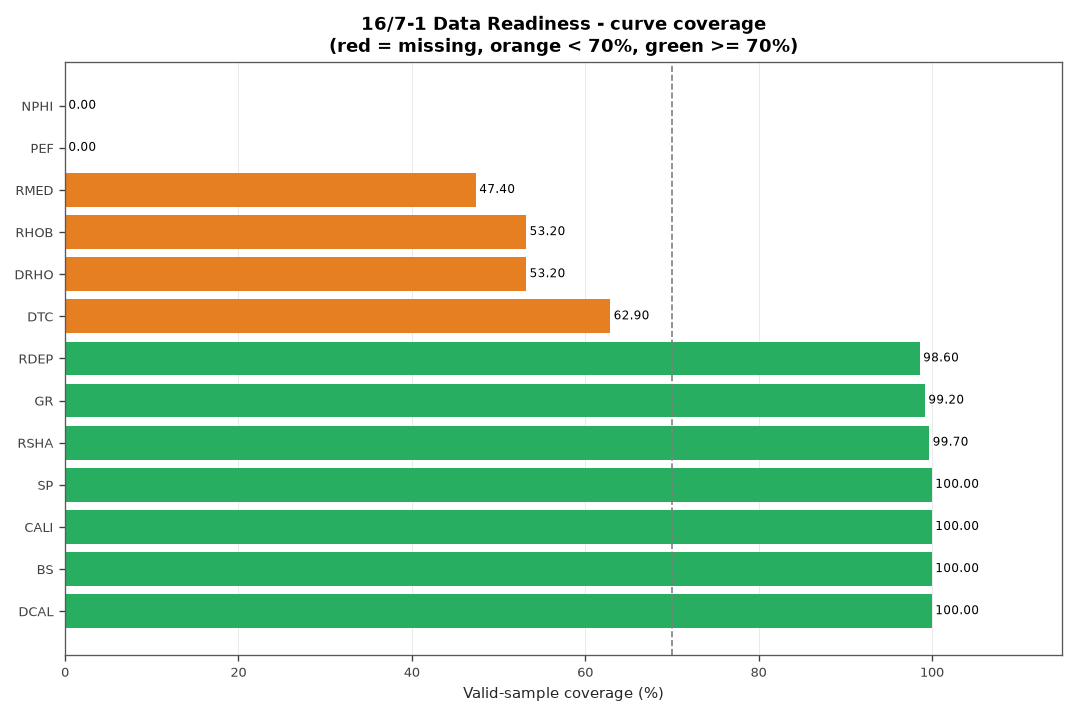

Missing curves : 2
Partial (<70%) : 4


In [5]:
from petrophys.visualization import create_bar_comparison

# First deliverable figure: curve-coverage bar chart via the library bar helper.
# Order the bars by coverage (ascending) so missing/partial curves surface at top.
rd = readiness.sort_values("coverage_%").reset_index(drop=True)
colors = []
for _, r in rd.iterrows():
    if r["status"] == "MISSING":
        colors.append("#c0392b")       # red - missing
    elif r["coverage_%"] < 70:
        colors.append("#e67e22")       # orange - partial
    else:
        colors.append("#27ae60")       # green - good

fig, ax = create_bar_comparison(
    rd["curve"].tolist(), rd["coverage_%"].values,
    horizontal=True, colors=colors, value_labels=True, figsize=(9, 6),
    xlabel="Valid-sample coverage (%)",
    title="16/7-1 Data Readiness - curve coverage\n(red = missing, orange < 70%, green >= 70%)",
)
ax.set_xlim(0, 115)
ax.axvline(70, ls="--", color="grey", lw=1)
plt.tight_layout()
plt.show()

n_missing = int((readiness["status"] == "MISSING").sum())
n_partial = int(((readiness["status"] == "present") & (readiness["coverage_%"] < 70)).sum())
print("Missing curves :", n_missing)
print("Partial (<70%) :", n_partial)

### 4.2 Deep resistivity (RDEP) above the reliable range - detect, flag, explain

**Why this matters.** Archie's equation gives $S_w \propto \sqrt{R_w / (R_t\,\phi^m)}$. A deep
resistivity reading of thousands of ohm.m drives Archie $S_w$ towards zero whatever the rock is,
so such samples must not reach the saturation step unexamined. Above about 2000 ohm.m most
resistivity tools are also outside their reliable range, so the number itself is uncertain.

The cause matters as much as the flag. In a clastic reservoir, isolated extreme readings may be a
tool problem. A long, continuous run of them usually is not: it is the true response of very
resistive rock. Evaporites (halite and anhydrite) have almost no conductive pore water, and the
16/7-1 well drilled the Zechstein salt in its lower part.

`apply_value_range_qc` carries a range for each curve family. For RDEP/RT the range is
**0.01-2000 ohm.m**; finite values outside it are set to NaN (flagged, not silently kept). SP
carries its own rule (**-500 to +500 mV**), which catches the impossible spikes seen in the
readiness table.

We capture a *before* copy of RDEP, apply the QC, then ask the well's own lithology log what the
flagged samples are.

In [6]:
rdep_before = well.get("RDEP").data.copy()

# Apply value-range QC to the resistivity + SP curves (returns a per-curve report)
qc_report = apply_value_range_qc(well, ["RDEP", "RMED", "RSHA", "SP", "GR", "RHOB"])
rdep_after = well.get("RDEP").data.copy()

# summarise what changed
for item in qc_report:
    if item["changed"]:
        print("%-6s cap [%.2f, %.1f]  set-NaN=%d  (below=%d, above=%d)"
              % (item["curve"], item["low"], item["high"],
                 item["changed"], item["below"], item["above"]))

print()
print("RDEP off-scale (flagged) samples :", int(np.sum(np.isfinite(rdep_before) & np.isnan(rdep_after))))
print("RDEP max before :", round(float(np.nanmax(rdep_before)), 1), "ohm.m")
print("RDEP max after  :", round(float(np.nanmax(rdep_after)), 1), "ohm.m")
print()
print(value_range_qc_note(qc_report))

RDEP   cap [0.01, 2000.0]  set-NaN=2954  (below=4, above=2950)
RMED   cap [0.01, 2000.0]  set-NaN=3  (below=3, above=0)
SP     cap [-500.00, 500.0]  set-NaN=136  (below=136, above=0)

RDEP off-scale (flagged) samples : 2954
RDEP max before : 4858.2 ohm.m
RDEP max after  : 1997.0 ohm.m

VALUE RANGE QC: finite values outside configured ranges were set to NaN; SW/SWA and SXO/SWXO/SWXOA were clipped to 0-1. Changed: RDEP set NaN=2954 (<0.01:4, >2000.0:2950); RMED set NaN=3 (<0.01:3, >2000.0:0); SP set NaN=136 (<-500.0:136, >500.0:0).


In [7]:
# What rock are the flagged RDEP samples in? Ask the well's own lithology log.
rdep_flag_qc = np.isfinite(rdep_before) & np.isnan(rdep_after)
names = {21: "halite", 22: "anhydrite"}
codes = lith_code[rdep_flag_qc]
print("Flagged RDEP samples: %d, %.1f - %.1f m"
      % (rdep_flag_qc.sum(), well.depth[rdep_flag_qc].min(), well.depth[rdep_flag_qc].max()))
for code, label in names.items():
    print("  coded %-9s : %5d samples" % (label, np.sum(codes == code)))
uncoded = rdep_flag_qc & ~np.isfinite(lith_code)
other = rdep_flag_qc & np.isfinite(lith_code) & ~np.isin(lith_code, list(names))
print("  other codes      : %5d samples" % other.sum())
print("  no lithology code: %5d samples  (median RHOB %.2f g/cm3, median GR %.1f gAPI)"
      % (uncoded.sum(), np.nanmedian(well.get("RHOB").data[uncoded]),
         np.nanmedian(well.get("GR").data[uncoded])))

Flagged RDEP samples: 2954, 1738.3 - 2620.4 m
  coded halite    :  2579 samples
  coded anhydrite :    57 samples
  other codes      :     4 samples
  no lithology code:   314 samples  (median RHOB 2.06 g/cm3, median GR 4.8 gAPI)


Almost every flagged sample lies in rock the well's own `LITHOLOGY_GEOLINK` curve codes as
halite or anhydrite. The uncoded remainder reads a density near 2.05 g/cm3 and a gamma ray of a
few gAPI - the halite response (about 2.03 g/cm3 and near-zero GR). So these readings are **real
evaporite resistivity, not a tool fault**: the QC removes them because they are beyond the tool's
reliable range and because salt is not reservoir, not because the rock reads "impossibly" high.
The QC also caught a handful of near-zero (negative) resistivities, and the SP rule nulled the
impossible negative spikes. The plot below shows deep resistivity before and after on a log scale.

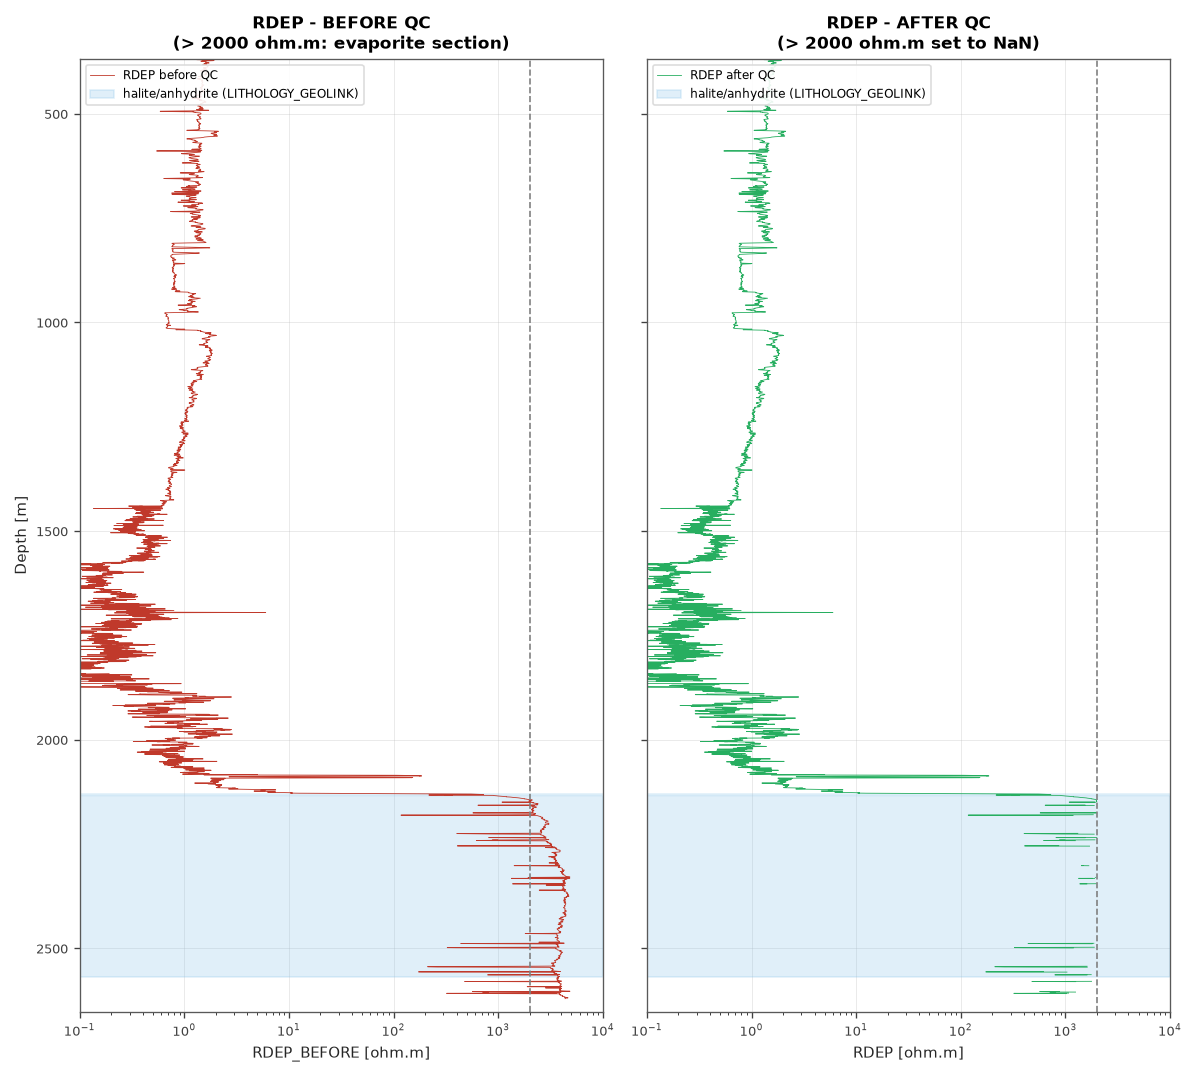

In [8]:
from petrophys.visualization import LogPlot

# Attach the pre-QC RDEP so the library LogPlot can render before vs after on a
# shared depth axis. (RDEP on the well is already the QC'd / capped version.)
well.add_curve("RDEP_BEFORE", rdep_before, unit="ohm.m",
               description="Deep resistivity before value-range QC")

lp = LogPlot(well, figsize=(10, 9))
lp.create_figure(n_tracks=2)
lp.add_curve(0, "RDEP_BEFORE", color="#c0392b", log_scale=True, xlim=(0.1, 1e4),
             label="RDEP before QC")
lp.axes[0].axvline(2000, ls="--", color="grey", lw=1)
lp.axes[0].set_title("RDEP - BEFORE QC\n(> 2000 ohm.m: evaporite section)", fontsize=10)
lp.add_curve(1, "RDEP", color="#27ae60", log_scale=True, xlim=(0.1, 1e4),
             label="RDEP after QC")
lp.axes[1].axvline(2000, ls="--", color="grey", lw=1)
# Shade the coded evaporites on both tracks so the cause of the plateau is visible.
evap = np.isin(lith_code, [21, 22])
for ax in lp.axes:
    ax.fill_betweenx(well.depth, 0.1, 1e4, where=evap, color="#85c1e9", alpha=0.25,
                     step="mid", label="halite/anhydrite (LITHOLOGY_GEOLINK)")
    ax.legend(loc="upper left", fontsize=7)
lp.axes[1].set_title("RDEP - AFTER QC\n(> 2000 ohm.m set to NaN)", fontsize=10)
lp.set_depth_range()
lp.show()


#### QC interpretation

The red plateau beyond the dashed 2000 ohm.m line coincides with the shaded halite/anhydrite
section; it is not a set of isolated spikes. After QC those samples are missing values and are
excluded from the water-saturation calculation - correctly, since salt is not reservoir - but the
lesson to carry is that the resistivity was *telling the truth about the rock*. A lithology mask
(section 4.7) is the right tool for evaporites; a range cap only removes the most extreme samples.

### 4.3 Washout / bad-hole detection

Density (RHOB) is a pad tool - in a washed-out hole the pad loses contact and RHOB reads too
low, inflating density porosity. `detect_washout` flags bad hole from **CALI - BS** (borehole
enlarged beyond bit size) and **|DRHO|** (large density correction). We will use these flags to
caveat porosity later.

In [9]:
wr = detect_washout(well)   # uses CALI, BS, DRHO automatically

stats = wr.statistics
depth_step = abs(well.step)
print("Washout    : %5.1f %% of hole  (%.1f m)"
      % (stats["washout_percent"], stats["washout_count"] * depth_step))
print("Large hole : %5.1f %%"          % stats["large_hole_percent"])
print("Bad hole   : %5.1f %% of hole  (%.1f m)"
      % (stats["bad_hole_percent"], stats["bad_hole_count"] * depth_step))
print()
print("Longest washout intervals (top, bottom) in m:")
long_iv = sorted(wr.washout_intervals, key=lambda t: t[1] - t[0], reverse=True)[:5]
for top, bot in long_iv:
    print("   %8.1f - %8.1f   (%.1f m)" % (top, bot, bot - top))

bad_hole_flag = wr.bad_hole_flag

Washout    :  26.2 % of hole  (597.4 m)
Large hole :   0.0 %
Bad hole   :  26.2 % of hole  (597.4 m)

Longest washout intervals (top, bottom) in m:
     2016.3 -   2083.4   (67.1 m)
     2129.2 -   2174.2   (45.0 m)
     2181.2 -   2224.5   (43.3 m)
     1579.5 -   1609.7   (30.2 m)
     1461.7 -   1490.4   (28.7 m)


The bad-hole flag marks the intervals where we will treat RHOB-derived porosity with
suspicion. We now have three QC layers registered: **missing curves**, **off-scale resistivity
(flagged)**, and **washout (flagged)**. Time to recover the missing neutron.

### 4.4 Validating the imputer BEFORE we trust it

We will use `PretrainedCurveImputer` - a pretrained model pack (XGBoost / random-forest / kNN)
trained on the wider GeoLink dataset - to synthesise the missing NPHI from the curves 16/7-1
*does* have. But there is a trap: **there is no NPHI ground truth in this well**, so we cannot
directly check the synthetic NPHI's accuracy.

The professional workaround is a **blank-and-restore test**: take a curve that *is* present and
trusted (here **RHOB** over its measured interval), artificially null it out over a test block,
ask the imputer to reconstruct it from companion curves, and compare the reconstruction against
the truth we hid. If the model reproduces a real curve well, we gain some justified confidence in
the model - and we quantify the error we should carry.

First, inspect the model pack.

In [10]:
imputer = PretrainedCurveImputer.from_pretrained()
print("Model pack path :", default_pretrained_model_path().name)
print("Algorithms      :", imputer.model_names)
print("Target curves   :", imputer.target_curves)
print()
# What does the imputer need to predict NPHI, and do we have those features?
nphi_entry = imputer.model_pack["models"]["xgboost"]["NPHI"]
nphi_features = nphi_entry["features"] if isinstance(nphi_entry, dict) else []
print("Features the XGBoost NPHI model expects:")
print("  ", nphi_features)
present = [f for f in nphi_features if well.has_curve(f)]
absent  = [f for f in nphi_features if not well.has_curve(f)]
print("Present in 16/7-1 :", present)
print("Absent  in 16/7-1 :", absent, "(model handles missing features gracefully)")

Model pack path : geolink_curve_imputation.joblib
Algorithms      : ['knn', 'rf', 'xgboost']
Target curves   : ['DTC', 'NPHI', 'RHOB']

Features the XGBoost NPHI model expects:
   ['BS', 'CALI', 'DRHO', 'DTC', 'DTS', 'GR', 'PEF', 'RDEP', 'RHOB', 'RMED', 'RSHA', 'RXO', 'SP']
Present in 16/7-1 : ['BS', 'CALI', 'DRHO', 'DTC', 'GR', 'RDEP', 'RHOB', 'RMED', 'RSHA', 'SP']
Absent  in 16/7-1 : ['DTS', 'PEF', 'RXO'] (model handles missing features gracefully)


The imputer needs at least 2 companion curves per sample (`min_available_features=2`) and
ignores features the well lacks (the absent list printed above). With the usable feature curves
present here, that condition is met over most of the hole.

**The safety rail - read this before Section 4.5.** `impute_missing` only *fills null samples in
a curve that already exists*; for an absent curve it raises `KeyError`. Lesson 13 explains why
this is deliberate: predicting a curve the well never logged is **prediction, not gap-filling**,
and its error is larger than any gap-filling test can show. Petrophys has no supported call that
creates a missing curve.

Section 4.5 nevertheless synthesises NPHI by first adding an **all-NaN placeholder** curve, which
deliberately overrides that rail. We accept the override here only under three conditions, and you
should apply the same ones if you ever do this:

1. **The error is unknown, and at least as large as the blank-and-restore error.** The test below
   measures gap-filling on RHOB; a never-logged NPHI can only be worse.
2. **The synthetic curve is labelled as synthetic everywhere** - in its description, in the
   readiness report and in the plots.
3. **It never enters the pay number and is never shown as a log.** The predicted NPHI feeds only a
   supporting porosity printed for comparison; the pay cutoffs use density porosity from measured
   RHOB, and the composite plot shows measured and measured-derived curves only.

The risk if you skip these conditions: a plausible-looking synthetic neutron quietly drives
porosity, gas flags and net pay, and nobody downstream can tell it was never measured.

For the validation here, RHOB already exists, so we just blank part of it - the supported use.
Now run the blank-and-restore on RHOB using the **xgboost** model.

In [11]:
# Work on a copy so we never corrupt the real well
val_well = copy.deepcopy(well)
rhob_truth = val_well.get("RHOB").data.copy()

# Choose a test block INSIDE the measured RHOB interval (so we have truth to compare against)
valid_idx = np.where(np.isfinite(rhob_truth))[0]
BLOCK = 500
start = valid_idx[len(valid_idx) // 2]                 # middle of the measured section
test_idx = valid_idx[(valid_idx >= start) & (valid_idx < start + BLOCK)]
test_mask = np.zeros(val_well.n_samples, dtype=bool)
test_mask[test_idx] = True

# Blank the test block
d = val_well.get("RHOB").data.copy()
d[test_mask] = np.nan
val_well.get("RHOB").data = d

top_m, bot_m = float(well.depth[test_idx[0]]), float(well.depth[test_idx[-1]])
print("Blanked RHOB test block : %.1f - %.1f m  (%d samples)" % (top_m, bot_m, test_mask.sum()))

# Impute the blanked RHOB
res_val = imputer.impute_missing(val_well, "RHOB", model_name="xgboost", inplace=True)
rhob_pred = val_well.get("RHOB").data

# Error stats over ONLY the blanked block where we have hidden truth
both = test_mask & np.isfinite(rhob_truth) & np.isfinite(rhob_pred)
err = rhob_pred[both] - rhob_truth[both]
mae  = float(np.mean(np.abs(err)))
rmse = float(np.sqrt(np.mean(err ** 2)))
bias = float(np.mean(err))
# correlation
r = float(np.corrcoef(rhob_truth[both], rhob_pred[both])[0, 1])

print()
print("Blank-and-restore error on hidden RHOB truth (n=%d):" % both.sum())
print("   MAE   = %.4f g/cm3" % mae)
print("   RMSE  = %.4f g/cm3" % rmse)
print("   Bias  = %+.4f g/cm3" % bias)
print("   Corr  = %.3f" % r)

# Decompose by hole condition: most of this test block sits inside the washout
# flag (section 4.3), where the measured RHOB "truth" is itself suspect (pad off
# the borehole wall). Report both populations so the headline RMSE is honest.
in_wash  = both & bad_hole_flag
in_gauge = both & ~bad_hole_flag
err_w = rhob_pred[in_wash] - rhob_truth[in_wash]
err_g = rhob_pred[in_gauge] - rhob_truth[in_gauge]
rmse_wash  = float(np.sqrt(np.mean(err_w ** 2)))
rmse_gauge = float(np.sqrt(np.mean(err_g ** 2)))
print()
print("Split by hole condition (washout flag from 4.3):")
print("   inside washout : n=%3d (%2.0f%%)  RMSE = %.4f g/cm3  <- 'truth' itself suspect"
      % (in_wash.sum(), 100.0 * in_wash.sum() / both.sum(), rmse_wash))
print("   in-gauge hole  : n=%3d (%2.0f%%)  RMSE = %.4f g/cm3  <- trustworthy truth"
      % (in_gauge.sum(), 100.0 * in_gauge.sum() / both.sum(), rmse_gauge))

Blanked RHOB test block : 2036.9 - 2112.9 m  (500 samples)

Blank-and-restore error on hidden RHOB truth (n=500):
   MAE   = 0.1173 g/cm3
   RMSE  = 0.1735 g/cm3
   Bias  = -0.0617 g/cm3
   Corr  = 0.562

Split by hole condition (washout flag from 4.3):
   inside washout : n=432 (86%)  RMSE = 0.1101 g/cm3  <- 'truth' itself suspect
   in-gauge hole  : n= 68 (14%)  RMSE = 0.3800 g/cm3  <- trustworthy truth


**Interpretation of the error.** The headline RMSE (printed above) is a real error on a curve that
spans roughly 1.7-3.0 g/cm3; the next cell converts it into density-porosity units. One honest
caveat before we lean on it: **most of the test block sits inside the washout flag**, where the
measured RHOB "truth" is itself suspect. The split tells the real story - the error against the
trustworthy in-gauge minority is much larger than the headline, so the headline is a *friendly*
estimate of the imputer's error, not a conservative one. The imputer captures the *trend*
(positive correlation) but should **not** be treated as a substitute for a real log: good enough
to inform, not good enough to book reserves on.

In [12]:
RHO_MA, RHO_FL = 2.65, 1.0   # sandstone matrix, fresh fluid - the density-porosity transform below
print("RHOB RMSE -> density-porosity error (divide by rho_ma - rho_fl = %.2f g/cm3):" % (RHO_MA - RHO_FL))
print("   headline block : %.3f g/cm3 -> +/-%.2f v/v" % (rmse, rmse / (RHO_MA - RHO_FL)))
print("   in-gauge only  : %.3f g/cm3 -> +/-%.2f v/v" % (rmse_gauge, rmse_gauge / (RHO_MA - RHO_FL)))
print("In-gauge RMSE is %.1fx the headline RMSE." % (rmse_gauge / rmse))

RHOB RMSE -> density-porosity error (divide by rho_ma - rho_fl = 1.65 g/cm3):
   headline block : 0.174 g/cm3 -> +/-0.11 v/v
   in-gauge only  : 0.380 g/cm3 -> +/-0.23 v/v
In-gauge RMSE is 2.2x the headline RMSE.


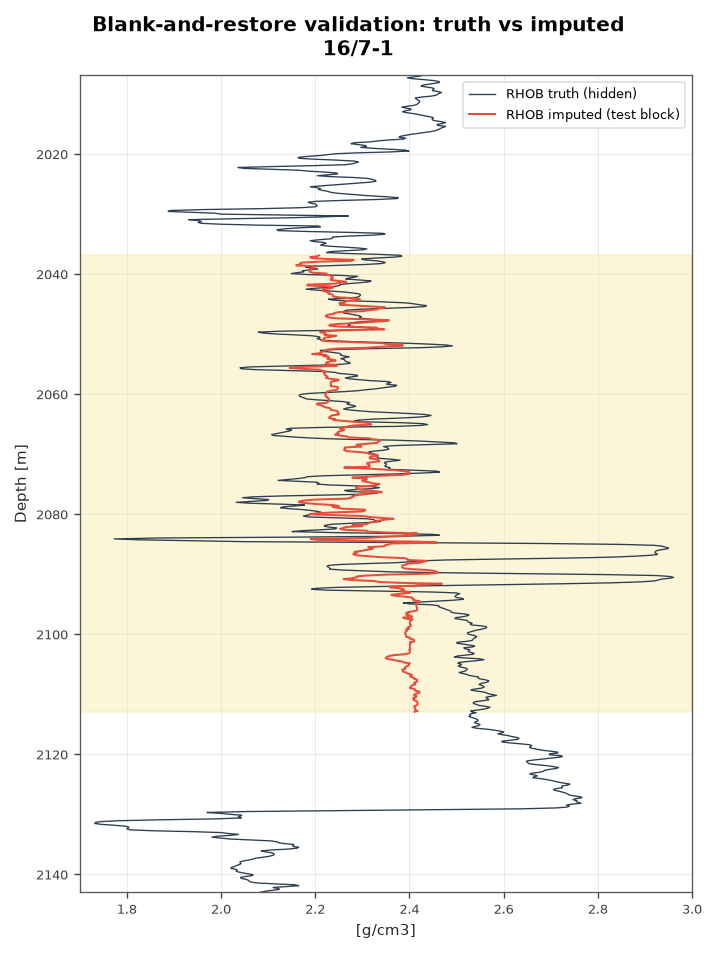

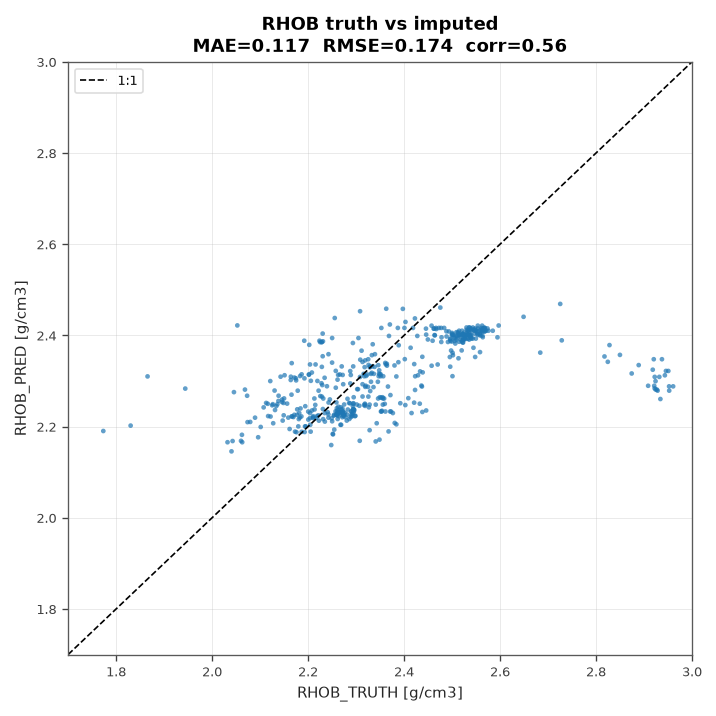

In [13]:
from petrophys.visualization import LogPlot, create_crossplot

# Attach the hidden truth and the imputed reconstruction to the validation well so
# the library plotters can render them. RHOB_PRED shows only the test block.
val_well.add_curve("RHOB_TRUTH", rhob_truth, unit="g/cm3", description="RHOB hidden truth")
val_well.add_curve("RHOB_PRED", np.where(test_mask, rhob_pred, np.nan), unit="g/cm3",
                   description="RHOB imputed over the blank-restore block")

# Panel A: blank-and-restore overlay (truth vs imputed) via the library LogPlot.
lp = LogPlot(val_well, figsize=(6, 8))
lp.create_figure(n_tracks=1)
lp.add_curve(0, "RHOB_TRUTH", color="#2c3e50", linewidth=0.8, xlim=(1.7, 3.0),
             label="RHOB truth (hidden)")
lp.add_curve(0, "RHOB_PRED", color="#e74c3c", linewidth=1.2, xlim=(1.7, 3.0),
             label="RHOB imputed (test block)")
lp.axes[0].axhspan(top_m, bot_m, color="#f9e79f", alpha=0.4)
lp.set_depth_range(top_m - 30, bot_m + 30)
lp.add_title("Blank-and-restore validation: truth vs imputed")
lp.show()

# Panel B: identity crossplot of truth vs imputed over the test block via the
# library crossplot, with a 1:1 identity line.
cp = create_crossplot(
    val_well, "RHOB_TRUTH", "RHOB_PRED", depth_range=(top_m, bot_m),
    xlim=(1.7, 3.0), ylim=(1.7, 3.0), marker_size=8, figsize=(6, 6),
    title="RHOB truth vs imputed\nMAE=%.3f  RMSE=%.3f  corr=%.2f" % (mae, rmse, r),
)
cp.add_line([1.7, 3.0], [1.7, 3.0], color="black", linestyle="--", label="1:1")
cp.show()

### 4.5 Predicting the genuinely-missing curve (NPHI) - a deliberate override

Now we apply the imputer to the real problem: the absent neutron log. As explained in 4.4, this
**overrides the imputer's safety rail**: we add an all-NaN `NPHI` placeholder, labelled as
synthetic, and let the imputer fill it from the present companion curves (including the
mis-scaled DTC).

We keep a permanent record of **which depths carry predicted NPHI** so downstream results can be
flagged, and then test the prediction where the physics is known.

In [14]:
# DELIBERATE OVERRIDE of the imputer's safety rail (see 4.4): the imputer refuses to create
# an absent curve, so we add an all-NaN placeholder first. The result is prediction, not
# gap-filling - it is labelled synthetic and kept out of the pay calculation.
if not well.has_curve("NPHI"):
    well.add_curve("NPHI", np.full(well.n_samples, np.nan),
                   unit="v/v", description="Neutron porosity (ML-predicted - SYNTHETIC, never logged)")

res_nphi = imputer.impute_missing(well, "NPHI", model_name="xgboost", inplace=True)

nphi = well.get("NPHI").data
# Depths where NPHI is synthetic (all of them here, since NPHI was 100% missing)
nphi_imputed_mask = np.isfinite(nphi)   # every filled sample is synthetic

print("NPHI imputation summary")
print("  model          :", res_nphi.model_name)
print("  features used  :", res_nphi.features_used)
print("  samples imputed:", res_nphi.imputed_count, "(skipped: %d)" % res_nphi.skipped_count)
print("  NPHI range     : %.3f - %.3f v/v" % (np.nanmin(nphi), np.nanmax(nphi)))
print("  synthetic frac : %.1f %% of the well" % (100.0 * nphi_imputed_mask.mean()))

NPHI imputation summary
  model          : xgboost
  features used  : ['BS', 'CALI', 'DRHO', 'DTC', 'GR', 'RDEP', 'RHOB', 'RMED', 'RSHA', 'SP']
  samples imputed: 14986 (skipped: 0)
  NPHI range     : 0.033 - 0.485 v/v
  synthetic frac : 100.0 % of the well


In [15]:
# Where the physics is known, check the prediction. Real neutron porosity in halite is about
# -0.03 v/v and in anhydrite about -0.02 to 0 (Schlumberger log-interpretation charts).
for code, label, expected in ((21, "halite", "about -0.03"), (22, "anhydrite", "about -0.02 to 0")):
    sel = lith_code == code
    print("Predicted NPHI in %-9s: median %.3f v/v over %d samples (real: %s)"
          % (label, np.nanmedian(nphi[sel]), sel.sum(), expected))

Predicted NPHI in halite   : median 0.186 v/v over 2716 samples (real: about -0.03)
Predicted NPHI in anhydrite: median 0.117 v/v over 149 samples (real: about -0.02 to 0)


#### Provenance warning

Every NPHI sample in this well is predicted, and the check above shows the prediction is
**physically wrong in the evaporites**: it reports a porous-rock neutron reading where halite and
anhydrite read about zero. Any porosity or saturation result that uses this NPHI is model-derived,
must keep an imputation flag, and here should not be trusted at all in the salt.

The predicted NPHI range is printed above. Its error is **unknown** in general and demonstrably
large in the salt: the blank-and-restore bounds gap-filling on RHOB from below, and a curve that was
never logged can only be worse. Crucially, **100% of NPHI is predicted** - so any neutron-density
porosity is only as good as the model.

That is why the primary porosity below rests on the **measured RHOB**, the N-D porosity built with
the predicted NPHI is printed for comparison only, and the composite plot in Part 5 does not show
the predicted NPHI as a log.

### 4.6 Interpretation on the mixed (measured + imputed) dataset

With QC done and NPHI recovered, we run a standard clastic evaluation, referencing the tutorial
mechanics (see Part A porosity / saturation lessons):

1. **Vcl** from GR (linear) - GR is essentially fully measured, so Vcl is the most trustworthy input.
2. **Density porosity** $\phi_D$ from measured RHOB (matrix 2.65, fluid 1.0).
3. **Neutron-density porosity** $\phi_{ND}$ from measured RHOB + **predicted** NPHI - flagged,
   printed for comparison only (it is wrong in the salt, section 4.5).
4. **Effective porosity** $\phi_e$ from $\phi_D$ with the Vcl shale correction (our primary
   PHIE, resting on *measured* density).
5. **Archie $S_w$** using the QC'd RDEP, with **assumed** $R_w$ (flagged - no formation-water
   sample), $a{=}1$, $m{=}n{=}2$.

We flag every assumption inline.

In [16]:
ASSUMED_RW = 0.05      # ohm.m at formation temperature - ASSUMED (no water sample) - FLAG
A, M, N = 1.0, 2.0, 2.0 # standard clastic Archie exponents - ASSUMED - FLAG

gr   = well.get("GR").data
rhob = well.get("RHOB").data
rdep = well.get("RDEP").data          # already QC'd (off-scale -> NaN)

# 1) Vcl from GR (percentiles as clean/shale baselines)
gr_clean = float(np.nanpercentile(gr, 5))
gr_shale = float(np.nanpercentile(gr, 95))
vcl = np.clip(vcl_from_gr(gr, gr_clean, gr_shale, method="linear"), 0, 1)

# 2) Density porosity from MEASURED RHOB
phid = density_porosity(rhob, rhob_matrix=RHO_MA, rhob_fluid=RHO_FL)
phid = np.clip(phid, 0, 0.5)

# 3) Neutron-density porosity using MEASURED RHOB + IMPUTED NPHI (supporting only)
phind = nd_weighted_porosity(nphi, phid)
phind = np.clip(phind, 0, 0.5)

# 4) Effective porosity from density (primary), shale-corrected
phie = effective_porosity(phid, vcl, phi_clay=0.15)
phie = np.clip(phie, 0, 0.5)

# 5) Archie Sw on QC'd deep resistivity
with np.errstate(invalid="ignore", divide="ignore"):
    sw = archie(rdep, ASSUMED_RW, phie, a=A, m=M, n=N)
sw = np.clip(sw, 0, 1)

print("GR clean/shale baselines : %.1f / %.1f gAPI" % (gr_clean, gr_shale))
print("  (vcl_from_gr clamps the clean anchor to <=20 and the shale anchor to >=100 API,")
print("   so the effective endpoints are %.1f / %.1f gAPI)"
      % (min(gr_clean, 20.0), max(gr_shale, 100.0)))
print("PHID  (density)  mean    : %.3f v/v" % np.nanmean(phid))
print("PHIND (N-D, uses imputed): %.3f v/v" % np.nanmean(phind))
print("PHIE  (effective)  mean  : %.3f v/v" % np.nanmean(phie))
print("Sw (Archie) mean         : %.3f v/v" % np.nanmean(sw))
print()
print("ASSUMPTIONS FLAGGED: Rw=%.3f ohm.m (assumed), a=%.1f m=%.1f n=%.1f (assumed)"
      % (ASSUMED_RW, A, M, N))

GR clean/shale baselines : 3.7 / 98.2 gAPI
  (vcl_from_gr clamps the clean anchor to <=20 and the shale anchor to >=100 API,
   so the effective endpoints are 3.7 / 100.0 gAPI)
PHID  (density)  mean    : 0.298 v/v
PHIND (N-D, uses imputed): 0.261 v/v
PHIE  (effective)  mean  : 0.261 v/v
Sw (Archie) mean         : 0.947 v/v

ASSUMPTIONS FLAGGED: Rw=0.050 ohm.m (assumed), a=1.0 m=2.0 n=2.0 (assumed)


### 4.7 Net pay - with explicit uncertainty flags

We apply the clastic curriculum cutoffs and, critically, split the result into **firm** vs
**uncertain** net pay. Attribution matters here, so we decompose it before flagging:

- **Uncertain pay = washout-flagged pay, full stop.** Our PHIE is density-only, so the one
  data-quality problem that can sit *inside* booked pay is bad hole, where the pad-tool RHOB
  (hence porosity) is suspect.
- Depths with **no measured RHOB** have no PHIE (NaN), and depths where **RDEP was flagged
  off-scale** have no Sw - both fail the cutoffs by construction and are therefore **excluded
  from pay entirely**, not flagged. This is a conservative treatment that may hide unbooked pay.
- The **imputed NPHI has zero influence on the pay number** - it feeds only the supporting
  PHIND display, not the density-only PHIE used in the cutoffs.
- **One population the cutoffs cannot see: evaporites.** The recipe has no lithology mask. Halite
  reads about 2.03 g/cm3 on the density log, an apparent porosity near 0.38 on the 2.65 g/cm3
  sandstone matrix, and salt and anhydrite read very high resistivity, so Archie returns a low Sw:
  evaporites pass all three cutoffs. In 16/7-1 the samples flagged below lie almost entirely in rock
  that the well's own `LITHOLOGY_GEOLINK` curve codes as halite or anhydrite, or in uncoded salt
  near the base of the well (about 2568-2634 m). `pp.interpret` leaves evaporites out of net
  reservoir and pay - coded ones, and halite recognised from its log response where no code says
  so; evaporites seal reservoirs rather than form them (Warren, 2006).

The decomposition below is printed so a reviewer can audit each claim.

In [17]:
from petrophys.evaluation import STANDARD_CUTOFFS
_std = STANDARD_CUTOFFS["clastic"]
VCL_CUT, PHIE_CUT, SW_CUT = _std["vcl_cutoff"], _std["phie_cutoff"], _std["sw_cutoff"]
print("clastic standard cutoffs:", _std)

# Base reservoir + pay test
reservoir = (vcl <= VCL_CUT) & (phie >= PHIE_CUT)
pay = reservoir & (sw <= SW_CUT)

# Uncertainty attribution - decompose before flagging
rdep_flagged  = np.isfinite(rdep_before) & np.isnan(rdep)   # off-scale RDEP depths
rhob_measured = np.isfinite(rhob)                           # depths with real density

thick = abs(well.step)
gross = np.isfinite(gr).sum() * thick
def m(mask): return float(mask.sum() * thick)

print("Where can pay overlap a data-quality problem?")
print("  pay & washout-flagged hole : %6.1f m" % m(pay & bad_hole_flag))
print("  pay & off-scale RDEP       : %6.1f m  (no Sw there -> cannot pass the Sw cutoff)"
      % m(pay & rdep_flagged))
print("  pay & no measured RHOB     : %6.1f m  (no PHIE there -> cannot pass the PHIE cutoff)"
      % m(pay & ~rhob_measured))
print()

# Uncertain pay is therefore exactly the washout-flagged pay; the other two QC
# populations are excluded from pay upstream (conservative - may hide unbooked pay).
uncertain = pay & bad_hole_flag
firm      = pay & ~uncertain

print("Net-pay summary (cutoffs: Vcl<=%.2f, PHIE>=%.2f, Sw<=%.2f)"
      % (VCL_CUT, PHIE_CUT, SW_CUT))
print("  Gross logged interval : %8.1f m" % gross)
print("  Reservoir (rock)      : %8.1f m" % m(reservoir))
print("  Total net pay         : %8.1f m" % m(pay))
print("     - FIRM  net pay    : %8.1f m  (measured density + valid RDEP + in-gauge hole)" % m(firm))
print("     - UNCERTAIN net pay: %8.1f m  (washout-flagged)" % m(uncertain))
frac_uncertain = 100.0 * m(uncertain) / max(m(pay), 1e-9)
print("  Uncertain fraction    : %8.1f %% of net pay" % frac_uncertain)

clastic standard cutoffs: {'vcl_cutoff': 0.4, 'phie_cutoff': 0.08, 'sw_cutoff': 0.6}
Where can pay overlap a data-quality problem?
  pay & washout-flagged hole :   23.8 m
  pay & off-scale RDEP       :    0.0 m  (no Sw there -> cannot pass the Sw cutoff)
  pay & no measured RHOB     :    0.0 m  (no PHIE there -> cannot pass the PHIE cutoff)

Net-pay summary (cutoffs: Vcl<=0.40, PHIE>=0.08, Sw<=0.60)
  Gross logged interval :   2266.3 m
  Reservoir (rock)      :    756.7 m
  Total net pay         :     33.8 m
     - FIRM  net pay    :     10.1 m  (measured density + valid RDEP + in-gauge hole)
     - UNCERTAIN net pay:     23.8 m  (washout-flagged)
  Uncertain fraction    :     70.3 % of net pay


## 5. Integrated result - the interpretation plot

The summary figure below is the heart of the deliverable. It is a multi-track composite of
**measured curves and results derived from them**, with every QC flag drawn on top, so a reviewer
can see at a glance where the answer is firm and where it is not. The predicted NPHI is
deliberately left out: it was never logged and is physically wrong in the salt.

- **Track 1** - GR (measured) + washout shading.
- **Track 2** - RHOB (measured; the shading marks its *measured extent*).
- **Track 3** - deep resistivity after QC, with the >2000 ohm.m samples marked and the coded
  halite/anhydrite shaded.
- **Track 4** - PHIE (density-derived, shale-corrected).
- **Track 5** - Sw (Archie, assumed Rw).
- **Track 6** - the net-pay flag, split **firm (green)** vs **uncertain (hatched orange)**.

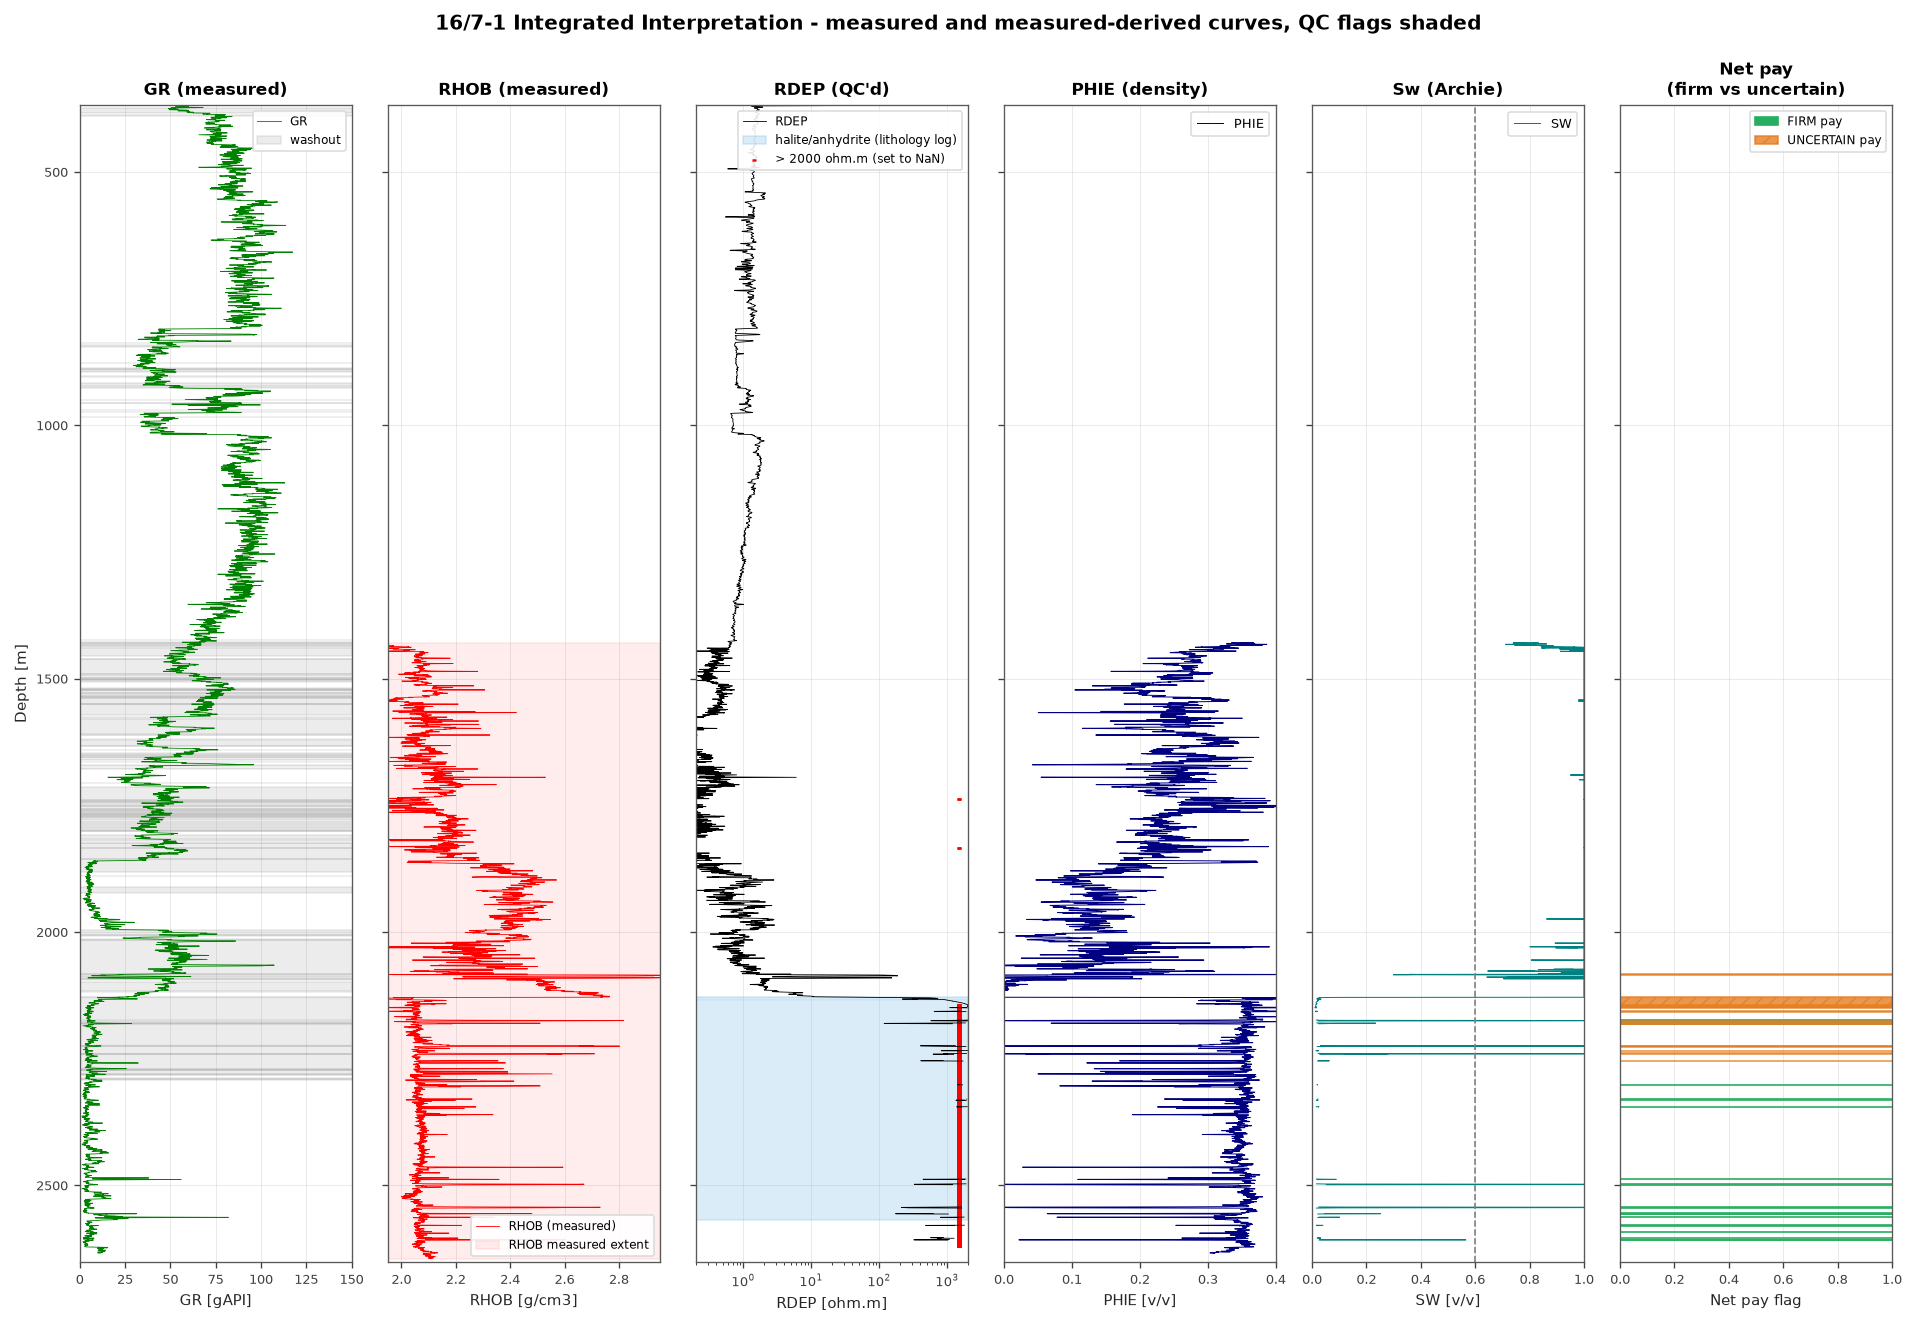

In [18]:
from petrophys.visualization import LogPlot

# Attach the interpretation curves and the firm/uncertain pay flags so the library
# LogPlot renders the whole composite. Only measured and measured-derived curves are
# drawn; the predicted NPHI is not shown as a log.
well.add_curve("VCL", vcl, unit="v/v")
well.add_curve("PHIE", phie, unit="v/v")
well.add_curve("SW", sw, unit="v/v")
well.add_curve("NET_PAY_FIRM", firm.astype(float), unit="")
well.add_curve("NET_PAY_UNCERTAIN", uncertain.astype(float), unit="")
evap = np.isin(lith_code, [21, 22])   # coded halite / anhydrite

lp = LogPlot(well, figsize=(16, 11))
lp.create_figure(n_tracks=6)

# Track 1: GR (measured) + washout shading
lp.add_curve(0, "GR", color="green", xlim=(0, 150))
lp.axes[0].fill_betweenx(well.depth, 0, 150, where=bad_hole_flag, color="grey",
                         alpha=0.15, step="mid", label="washout")
lp.axes[0].set_title("GR (measured)", fontsize=10)
lp.axes[0].legend(loc="upper right", fontsize=7)

# Track 2: RHOB (measured, solid; shading marks its MEASURED extent)
lp.add_curve(1, "RHOB", color="red", xlim=(1.95, 2.95), label="RHOB (measured)")
lp.axes[1].fill_betweenx(well.depth, 1.95, 2.95, where=np.isfinite(rhob),
                         color="red", alpha=0.07, step="mid", label="RHOB measured extent")
lp.axes[1].set_title("RHOB (measured)", fontsize=10)
lp.axes[1].legend(loc="lower right", fontsize=7)

# Track 3: deep resistivity (QC'd) + flagged samples + evaporite shading
lp.add_curve(2, "RDEP", color="black", log_scale=True, xlim=(0.2, 2000))
lp.axes[2].fill_betweenx(well.depth, 0.2, 2000, where=evap, color="#85c1e9", alpha=0.3,
                         step="mid", label="halite/anhydrite (lithology log)")
flagged_depths = well.depth[rdep_flagged]
lp.axes[2].scatter(np.full(flagged_depths.shape, 1500), flagged_depths, marker="_",
                   color="red", s=8, label="> 2000 ohm.m (set to NaN)")
lp.axes[2].set_title("RDEP (QC'd)", fontsize=10)
lp.axes[2].legend(loc="upper right", fontsize=7)

# Track 4: PHIE
lp.add_curve(3, "PHIE", color="navy", linewidth=0.6, xlim=(0, 0.4))
lp.axes[3].set_title("PHIE (density)", fontsize=10)

# Track 5: Sw
lp.add_curve(4, "SW", color="teal", linewidth=0.6, xlim=(0, 1))
lp.axes[4].axvline(SW_CUT, color="grey", ls="--", lw=1)
lp.axes[4].set_title("Sw (Archie)", fontsize=10)

# Track 6: net pay firm vs uncertain
lp.axes[5].fill_betweenx(well.depth, 0, 1, where=firm, color="#27ae60", step="mid",
                         label="FIRM pay")
lp.axes[5].fill_betweenx(well.depth, 0, 1, where=uncertain, color="#e67e22", alpha=0.8,
                         hatch="///", step="mid", label="UNCERTAIN pay")
lp.axes[5].set_xlim(0, 1); lp.axes[5].set_xlabel("Net pay flag")
lp.axes[5].set_title("Net pay\n(firm vs uncertain)", fontsize=10)
lp.axes[5].legend(loc="upper right", fontsize=7)

lp.set_depth_range()
lp.fig.suptitle(
    "16/7-1 Integrated Interpretation - measured and measured-derived curves, QC flags shaded",
    y=0.995, fontsize=12)
lp.show()

## 6. Interpretation & deliverable

### 6.1 The data readiness report (measured vs imputed)

This table is the auditable core of the deliverable - it states, curve by curve, what came from
the tool string and what came from the model.

In [19]:
readiness_report = pd.DataFrame([
    {"curve": "GR",   "source": "MEASURED", "coverage_%": round(100*well.get('GR').valid_count()/well.n_samples,1),
     "role": "Vcl (primary) + imputer feature", "trust": "HIGH"},
    {"curve": "CALI/BS/DCAL", "source": "MEASURED", "coverage_%": 100.0,
     "role": "washout / bad-hole QC", "trust": "HIGH"},
    {"curve": "RHOB", "source": "MEASURED (partial)", "coverage_%": round(100*np.isfinite(rhob).mean(),1),
     "role": "primary porosity (PHID/PHIE)", "trust": "MEDIUM (washout-flagged)"},
    {"curve": "DTC",  "source": "MEASURED (partial)", "coverage_%": round(100*well.get('DTC').valid_count()/well.n_samples,1),
     "role": "imputer feature", "trust": "LOW (mis-scaled, ~0.3x expected)"},
    {"curve": "RDEP", "source": "MEASURED (QC'd)", "coverage_%": round(100*np.isfinite(rdep).mean(),1),
     "role": "Archie Sw", "trust": "MEDIUM (>2000 ohm.m nulled; evaporites)"},
    {"curve": "NPHI", "source": "PREDICTED (XGBoost)", "coverage_%": round(100*nphi_imputed_mask.mean(),1),
     "role": "comparison N-D porosity only", "trust": "LOW (synthetic; wrong in salt)"},
    {"curve": "PEF",  "source": "MISSING", "coverage_%": 0.0,
     "role": "lithology (not attempted)", "trust": "N/A"},
])
print(readiness_report.to_string(index=False))

       curve              source  coverage_%                            role                                   trust
          GR            MEASURED        99.2 Vcl (primary) + imputer feature                                    HIGH
CALI/BS/DCAL            MEASURED       100.0           washout / bad-hole QC                                    HIGH
        RHOB  MEASURED (partial)        53.2    primary porosity (PHID/PHIE)                MEDIUM (washout-flagged)
         DTC  MEASURED (partial)        62.9                 imputer feature        LOW (mis-scaled, ~0.3x expected)
        RDEP     MEASURED (QC'd)        78.9                       Archie Sw MEDIUM (>2000 ohm.m nulled; evaporites)
        NPHI PREDICTED (XGBoost)       100.0    comparison N-D porosity only          LOW (synthetic; wrong in salt)
         PEF             MISSING         0.0       lithology (not attempted)                                     N/A


### 6.2 The caveated result

**Recommendation to management (honest version):**

- 16/7-1 supports a **defensible but uncertainty-bounded** interpretation, and its finding is
  negative. Over the section with *measured density, valid deep resistivity and in-gauge hole*,
  the cutoffs flag **firm net pay**, but the well's own lithology log places it in halite and in the
  uncoded salt near the base of the well (section 4.7): salt, not reservoir.
- The rest of the apparent net pay is **uncertain** - all of it because it sits in
  **washout-flagged hole**, where the pad-tool density (hence porosity) is suspect - and most of it
  is coded anhydrite or halite as well. The few remaining metres (silt, shaly silt and argillaceous
  limestone at about 2084-2133 m) lie at the top of the Zechstein evaporite section, and the NPD
  fact page reports 16/7-1 as a dry well with no shows. They are not upside either: **on today's
  data the well has no pay to book.**
- Two things a reviewer should see stated plainly. First, intervals with **no measured density**
  or with **RDEP above 2000 ohm.m** are not in the pay number at all - PHIE or Sw is NaN there, so
  they fail the cutoffs by construction; the high-resistivity ones are the salt itself. Second,
  the **predicted neutron does not drive the pay number** - PHIE is density-only, and the predicted
  NPHI, which is physically wrong in the salt (section 4.5), only feeds the PHIND value printed for
  comparison.
- **Before reusing this recipe**, (a) apply a lithology mask for the evaporites - the well's own
  `LITHOLOGY_GEOLINK` curve, plus a halite log-response test where it has no code - before any
  cutoff; (b) acquire a formation-water sample to replace the assumed $R_w$; (c) fix or re-acquire
  the sonic, which is stored on the wrong scale; and (d) repeat the density over the un-logged and
  washed-out intervals. No new resistivity log is needed: the >2000 ohm.m readings are the salt.

The value of this workflow is not that it invented data - it is that it made the well *usable*
today while drawing a bright, auditable line between what we measured and what we modelled, and
it found the lithology behind the most alarming-looking curve.

In [20]:
print("=" * 66)
print(" 16/7-1  FINAL CAVEATED NET-PAY RESULT")
print("=" * 66)
print("  Total net pay      : %6.1f m" % m(pay))
print("  FIRM net pay       : %6.1f m   <- defensible, measured-data-based" % m(firm))
print("  UNCERTAIN net pay  : %6.1f m   <- washout-flagged (RHOB porosity suspect)" % m(uncertain))
print("  Uncertain fraction : %6.1f %% of net pay" % frac_uncertain)
print("  (no-density and >2000 ohm.m RDEP intervals are EXCLUDED from pay entirely;")
print("   the firm and most uncertain metres are halite/anhydrite - see 4.7 and 6.2)")
print("-" * 66)
print("  Imputer credibility (blank-restore on RHOB):")
print("     MAE=%.3f  RMSE=%.3f g/cm3  corr=%.2f" % (mae, rmse, r))
print("     (in-gauge subset RMSE=%.3f g/cm3 - see the 4.4 caveat)" % rmse_gauge)
print("  Key assumptions FLAGGED: Rw=%.3f ohm.m, a=%.1f m=%.1f n=%.1f" % (ASSUMED_RW, A, M, N))
print("  Synthetic curves: NPHI (100% predicted - comparison only, wrong in salt, not plotted)")
print("  Mis-scaled input: DTC (~0.3x expected) - used as an imputer feature, so imputation is suspect")
print("=" * 66)

 16/7-1  FINAL CAVEATED NET-PAY RESULT
  Total net pay      :   33.8 m
  FIRM net pay       :   10.1 m   <- defensible, measured-data-based
  UNCERTAIN net pay  :   23.8 m   <- washout-flagged (RHOB porosity suspect)
  Uncertain fraction :   70.3 % of net pay
  (no-density and >2000 ohm.m RDEP intervals are EXCLUDED from pay entirely;
   the firm and most uncertain metres are halite/anhydrite - see 4.7 and 6.2)
------------------------------------------------------------------
  Imputer credibility (blank-restore on RHOB):
     MAE=0.117  RMSE=0.174 g/cm3  corr=0.56
     (in-gauge subset RMSE=0.380 g/cm3 - see the 4.4 caveat)
  Key assumptions FLAGGED: Rw=0.050 ohm.m, a=1.0 m=2.0 n=2.0
  Synthetic curves: NPHI (100% predicted - comparison only, wrong in salt, not plotted)
  Mis-scaled input: DTC (~0.3x expected) - used as an imputer feature, so imputation is suspect


## 7. Limitations & assumptions

An honest study lists its own weak points:

1. **NPHI is 100% predicted, and creating it overrode the imputer's safety rail.** The
   blank-and-restore validated the *model* at gap-filling a present curve, not this never-logged
   NPHI - there is no NPHI ground truth in 16/7-1, and in the salt the prediction is physically
   wrong (4.5). Treat the blank-and-restore RMSE (4.4) as a lower bound on its error, which is why
   NPHI never enters the pay number or the composite plot.
2. **DTC is mis-scaled** (about 0.3x the expected values, 4.1) and was still used as an imputer
   feature, so both the blank-and-restore errors and the predicted NPHI are contaminated by it.
3. **$R_w$ is assumed** (0.05 ohm.m at formation temperature). No formation-water sample. Sw
   scales roughly with $\sqrt{R_w}$, so a 2x error in $R_w$ moves Sw by ~40%.
4. **Archie exponents $a,m,n$ are textbook defaults** - no core-derived $m$/$n$ (unlike CS2).
5. **RDEP above 2000 ohm.m is flagged out, not corrected** - those depths have no Sw. Here they are
   the Zechstein evaporites, which are not reservoir anyway (4.2).
6. **PEF is unrecovered** - the pretrained model pack has no PEF model (its targets are printed
   in 4.4), and there is no measured PEF in this well to validate one against, so no lithology
   solution is built.
7. **No core, no formation tops** were used - this is a stand-alone log evaluation.
8. **No lithology mask.** The cutoffs cannot tell evaporites from reservoir (section 4.7), and the
   flagged pay here is almost all halite or anhydrite. A recipe for a well with salt should exclude
   the evaporite codes, as `pp.interpret` does, and test the halite log response (RHOB
   1.95-2.15 g/cm3, GR < 15 API, RT > 500 ohm.m) where the codes are missing.

Items 2-4 and 6 need new or corrected data (section 6.2); items 5 and 8 need no new data, only the
lithology log the well already carries.

## 8. Appendix - reproduce on another well

The recovery workflow is well-agnostic. To run it on any GeoLink-style LAS:

```python
import numpy as np
import petrophys as pp
from petrophys.preprocessing import apply_value_range_qc, detect_washout
from petrophys.preprocessing.imputation import PretrainedCurveImputer

well = pp.read("<your_file.las>")            # or pp.sample("15_9-14"), "25_5-1", ...

# 1. readiness: loop over a standard suite, compare valid_count()/n_samples
# 2. off-scale QC:
apply_value_range_qc(well, ["RDEP", "RMED", "RSHA", "SP"])
# 3. washout:
wr = detect_washout(well)
# 4. VALIDATE first (blank-and-restore a present curve) - the supported use:
imp = PretrainedCurveImputer.from_pretrained()
imp.impute_missing(well, "RHOB", model_name="xgboost")    # fills gaps in an existing curve
# 5. Only if you accept the override conditions of section 4.4:
if not well.has_curve("NPHI"):
    well.add_curve("NPHI", np.full(well.n_samples, np.nan), unit="v/v",
                   description="SYNTHETIC - never logged")
    imp.impute_missing(well, "NPHI", model_name="xgboost")
# 6. interpret with measured curves; keep synthetic curves out of the pay cutoffs.
```

**Key API reminders learned in this study:**
- `PretrainedCurveImputer.impute_missing` only *fills nulls in an existing curve* and raises
  `KeyError` for an absent one - a deliberate safety rail. Adding an all-NaN placeholder
  overrides it; do that only with the three conditions of section 4.4.
- The imputer needs `>= min_available_features` (default 2) companion curves per sample and
  ignores features the well lacks.
- `apply_value_range_qc` sets RDEP/RT outside 0.01-2000 ohm.m to NaN; SW/SXO are *clipped*.
- Always validate an imputer by blank-and-restore on a real curve **before** trusting its
  output, and carry the measured error as a lower bound on your uncertainty.

### Where this sits in the curriculum
CS4 completes the robustness arc: CS1 (full evaluation), CS2 (carbonate + core), CS3 (multiwell
screening), **CS4 (imperfect-data robustness)**, and CS5 (saturation-model sensitivity).

### Recap

- A **data-readiness table** against a standard suite shows what is missing (NPHI, PEF) and what is
  only partly recorded before any interpretation starts.
- **Out-of-range resistivity and washouts are flagged**, not silently corrected, and the cause is
  checked: the >2000 ohm.m readings are the evaporite section, not a tool fault. The sonic is on
  the wrong scale and is rated LOW.
- The imputer is **validated by blank-and-restore** on a present curve, and the in-gauge error is
  much larger than the headline - the honest number to carry.
- Predicting an absent NPHI **overrides a deliberate safety rail**; the prediction is physically
  wrong in the salt, so it is labelled synthetic, kept out of the pay number and not plotted.
- The deliverable is **firm vs uncertain net pay** plus a curve-by-curve readiness report - and a
  **lithology cross-check**: here the flagged metres are evaporites (halite and anhydrite), not
  reservoir.

### Exercises

1. **Algorithm choice.** Repeat the blank-and-restore with `model_name="rf"` and `"knn"`. Which
   has the lowest in-gauge RMSE?
2. **A different block.** Move the blank-and-restore block to an in-gauge section of the hole.
   How does the error compare with the headline here?
3. **Rw sensitivity.** Re-run the pay split with `ASSUMED_RW` of 0.03 and 0.08 ohm.m. How much of
   the firm pay survives?
4. **Without the mis-scaled sonic.** Repeat the blank-and-restore on a copy of the well with DTC
   removed (the imputer ignores features the well lacks). Does the in-gauge RMSE improve?
5. **Lithology mask.** Exclude GeoLink codes 21 (halite) and 22 (anhydrite) from `reservoir` and
   recompute the firm/uncertain split. What is left?

### What's next

**CS5** - saturation-model selection and parameter sensitivity on well 30/6-5.